In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn
%pip install pandas


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python3.14 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python3.14 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# import the dataset
import pandas as pd

# games files 
games = pd.read_csv('nfl-big-data-bowl-2027/games.csv')

# players files
players = pd.read_csv('nfl-big-data-bowl-2027/players.csv')

# print the games file
games.head()

,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
0,2023090700,59173,2023,REG,1,KC,DET
1,2023091000,59174,2023,REG,1,ATL,CAR
2,2023091001,59175,2023,REG,1,BAL,HOU
3,2023091002,59176,2023,REG,1,CLE,CIN
4,2023091003,59177,2023,REG,1,IND,JAX


In [3]:
# print players head
players.head()

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.0,10.0,10.0
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.0,11.0,11.0
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.0,13.0,13.0


# Clean the games dataset

In [4]:
# display the dataset 
print("--- Game Dataset Info ---")
display(games.info())

# Find NAN and zero values
print(" ")
print("--- Missing and NAN Values ---")
display(games.isnull().sum())

# clean the games by ensuring correct types
print(" ")
print("--- Print the games by data types")
games["season"] = games["season"].astype(int)
games["week"] = games["week"].astype(int)

print("\n Cleaned Games Summary:")
display(games.head())
display(games.describe())

--- Game Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1002 entries, 0 to 1001
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   game_id            1002 non-null   int64
 1   game_key           1002 non-null   int64
 2   season             1002 non-null   int64
 3   season_type        1002 non-null   str  
 4   week               1002 non-null   int64
 5   home_team_abbr     1002 non-null   str  
 6   visitor_team_abbr  1002 non-null   str  
dtypes: int64(4), str(3)
memory usage: 54.9 KB


None

 
--- Missing and NAN Values ---


game_id              0
game_key             0
season               0
season_type          0
week                 0
home_team_abbr       0
visitor_team_abbr    0
dtype: int64

 
--- Print the games by data types

 Cleaned Games Summary:


,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
0,2023090700,59173,2023,REG,1,KC,DET
1,2023091000,59174,2023,REG,1,ATL,CAR
2,2023091001,59175,2023,REG,1,BAL,HOU
3,2023091002,59176,2023,REG,1,CLE,CIN
4,2023091003,59177,2023,REG,1,IND,JAX


,game_id,game_key,season,week
count,1.002000e+03,1002.000000,1002.000000,1002.000000
mean,2.024182e+09,59674.500000,2024.000000,8.799401
std,8.557928e+05,290.167099,0.816904,5.922129
min,2.023080e+09,59173.000000,2023.000000,0.000000
25%,2.023121e+09,59423.250000,2023.000000,3.000000
50%,2.024103e+09,59674.500000,2024.000000,8.000000
75%,2.025092e+09,59925.750000,2025.000000,14.000000
max,2.026021e+09,60176.000000,2025.000000,23.000000


# Clean the Player dataset

In [5]:
# display the dataset 
print("--- Game Dataset Info")
display(players.info())

# Find NAN and zero values
print(" ")
print("--- Missing and NAN Values ---")
display(players.isnull().sum())

# Clean the games by ensuring correct types
# Fill missing draft information with placeholder or appropriate values
print(" ")
print("--- Print the games by data types ---")
players['draft_year'] = players['draft_year'].fillna(-1).astype(int)
players['draft_round'] = players['draft_round'].fillna(-1).astype(int)
players['draft_overall_pick'] = players["draft_overall_pick"].fillna(-1).astype(int)

# Convert birth data to datetime
players["birth_date"] = pd.to_datetime(players['birth_date'], format='%Y-%m-%d')

print("\n Cleaned Players Summary:")
display(players.head())

--- Game Dataset Info
<class 'pandas.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   nfl_id                   510 non-null    int64  
 1   display_name             510 non-null    str    
 2   draft_year               510 non-null    int64  
 3   nfl_position             510 non-null    str    
 4   birth_date               510 non-null    str    
 5   college_name             510 non-null    str    
 6   college_conference       510 non-null    str    
 7   draft_round              383 non-null    float64
 8   draft_pick_within_round  383 non-null    float64
 9   draft_overall_pick       383 non-null    float64
dtypes: float64(3), int64(2), str(5)
memory usage: 40.0 KB


None

 
--- Missing and NAN Values ---


nfl_id                       0
display_name                 0
draft_year                   0
nfl_position                 0
birth_date                   0
college_name                 0
college_conference           0
draft_round                127
draft_pick_within_round    127
draft_overall_pick         127
dtype: int64

 
--- Print the games by data types ---

 Cleaned Players Summary:


,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1,3.0,3
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1,6.0,6
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1,10.0,10
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1,11.0,11
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1,13.0,13


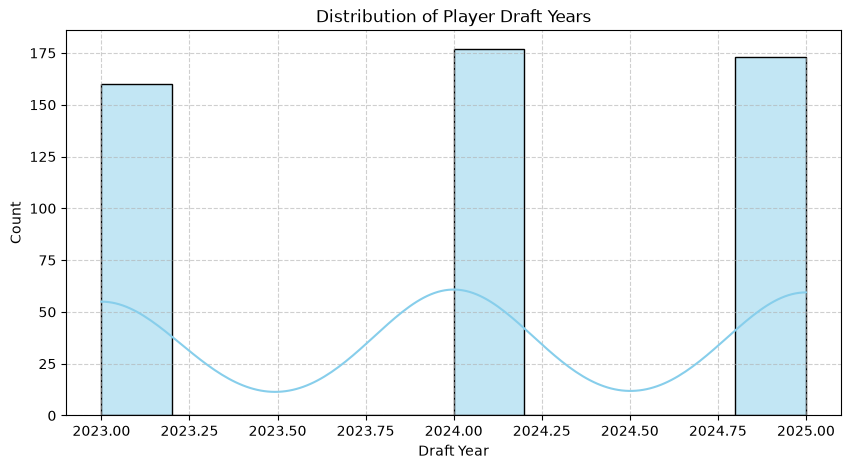

In [6]:
# Since we don't have a direct key linking individual players to the specific games inside 'games.csv',
# let's load a mapping table if available, or analyze them sequentially. Let's see if we can read player_play.csv
# to join them, or aggregate players by college/draft year and relate it to game trends.

import matplotlib.pyplot as plt
import seaborn as sns

# Let's plot the distribution of players' Draft Years
plt.figure(figsize=(10,5))
# histogram plot
sns.histplot(data=players[players['draft_year'] > 0], x='draft_year', bins=10, kde=True, color='skyblue')
# title of the graph
plt.title("Distribution of Player Draft Years")
# x label
plt.xlabel("Draft Year")
# y label
plt.ylabel("Count")
# plot grid 
plt.grid(True, linestyle="--", alpha=0.6)
# show the plot
plt.show()

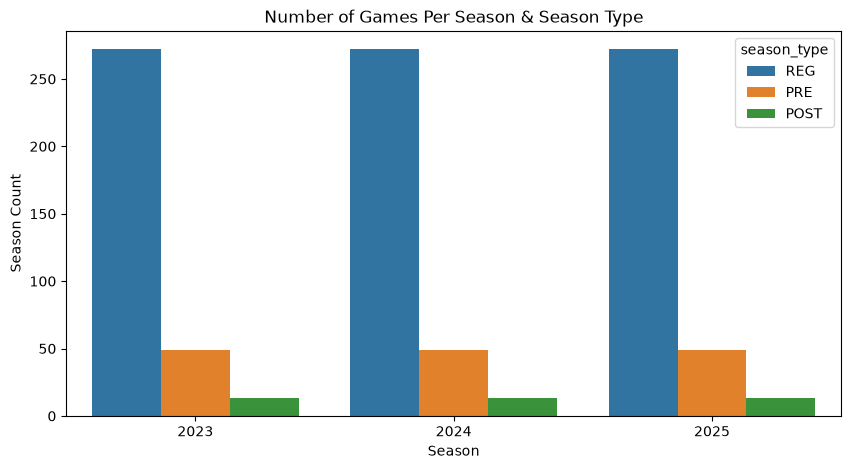

In [7]:
# Visualize Game by Counts by Season
plt.figure(figsize=(10,5))
# count plot 
sns.countplot(data=games, x="season", hue="season_type")
# title of the graph
plt.title("Number of Games Per Season & Season Type")
# x label
plt.xlabel("Season")
# y label
plt.ylabel("Season Count")
# plot show
plt.show()

Combined Dataset shape: (314197, 17)


,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1,3.0,3,2025121402,60054,2025,REG,15,HOU,ARI
1,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1,3.0,3,2025091500,59873,2025,REG,2,HOU,TB
2,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1,3.0,3,2023120307,59361,2023,REG,13,HOU,DEN
3,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1,3.0,3,2024101303,59590,2024,REG,6,NE,HOU
4,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1,3.0,3,2023110505,59301,2023,REG,9,HOU,TB


/var/folders/zj/hxcyq76x7p58zfw5j_v9jh5w0000gn/T/ipykernel_88136/1686908333.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=combined_df, x='nfl_position', palette='Set2', legend=False, order=combined_df['nfl_position'].value_counts().index)


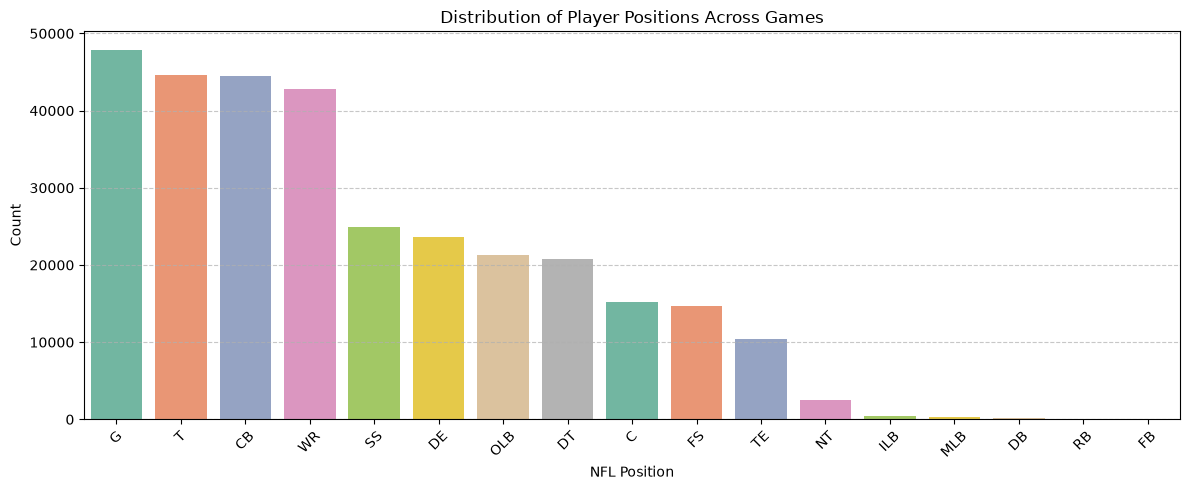

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the relationship mapping table
player_play = pd.read_csv('nfl-big-data-bowl-2027/player_play.csv')

# 2. Merge players with mapping, then with games
merged_players = pd.merge(players, player_play[['nfl_id', 'game_id']], on='nfl_id', how='inner')
combined_df = pd.merge(merged_players, games, on='game_id', how='inner')

# Combined Dataset Shape
print("Combined Dataset shape:", combined_df.shape)
display(combined_df.head())

# 3. Simple EDA: Distribution of player positions in games
plt.figure(figsize=(12, 5))
sns.countplot(data=combined_df, x='nfl_position', palette='Set2', legend=False, order=combined_df['nfl_position'].value_counts().index)
plt.title('Distribution of Player Positions Across Games')
plt.xlabel('NFL Position')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [9]:
# Load the player_play mapping dataset to connect games and players
player_play = pd.read_csv('nfl-big-data-bowl-2027/player_play.csv')

# Inspect columns
print("player_play columns:", player_play.columns.tolist())

# Merge players with player_play
merged_players_plays = pd.merge(players, player_play, on='nfl_id', how='inner')

# Merge the result with games
combined_df = pd.merge(merged_players_plays, games, on='game_id', how='inner')

print("Combined Dataset Shape:", combined_df.shape)
print("Combined Dataset Sample:")
display(combined_df.head(3))

player_play columns: ['game_id', 'play_id', 'team_abbr', 'nfl_id', 'lined_up_position', 'play_description', 'quarter', 'down', 'yards_to_go', 'possession_team', 'yardline_side', 'yardline_number', 'game_clock', 'pre_snap_home_score', 'pre_snap_visitor_score', 'play_direction', 'pre_snap_home_team_win_probability', 'pre_snap_visitor_team_win_probability', 'home_team_win_probability_added', 'visitor_team_win_probility_added', 'expected_points_added', 'expected_points', 'offense_formation', 'receiver_alignment', 'pass_result', 'pass_length', 'play_nullified_by_penalty', 'penalty_yards', 'pre_penalty_yards_gained', 'yards_gained', 'team_coverage_man_zone', 'team_coverage_type', 'in_motion_at_ball_snap', 'target', 'rec_yards', 'rush_yards', 'yards_after_catch', 'fumble', 'fumble_lost', 'route_ran', 'separation_at_pass_forward', 'cushion', 'expected_yards_after_catch', 'dropback_duration', 'extended_sack_allowed', 'pass_rushers_encountered', 'peak_pressure_probability_allowed', 'pressure_all

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick,...,time_to_pressure,time_to_qb_hurry,coverage_assignment,coverage_assignment_at_snap,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1,3.0,3,...,NaN,NaN,NaN,NaN,60054,2025,REG,15,HOU,ARI
1,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1,3.0,3,...,NaN,NaN,NO_ASSIGNMENT,NO_ASSIGNMENT,59873,2025,REG,2,HOU,TB
2,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1,3.0,3,...,NaN,NaN,NO_ASSIGNMENT,NO_ASSIGNMENT,59361,2023,REG,13,HOU,DEN


=== Statistical Metrics Summary ===


,yards_gained,expected_points_added,expected_points,pre_snap_home_team_win_probability
count,314197.000000,314197.000000,314197.000000,314194.000000
mean,5.183038,-0.053037,2.314289,0.537154
std,8.949774,1.454272,1.606048,0.306032
min,-99.000000,-12.896382,-2.899994,0.000760
25%,0.000000,-0.752888,1.134161,0.281416
50%,3.000000,-0.213721,2.134480,0.555932
75%,8.000000,0.708943,3.462250,0.803805
max,98.000000,8.968813,6.656688,0.999950


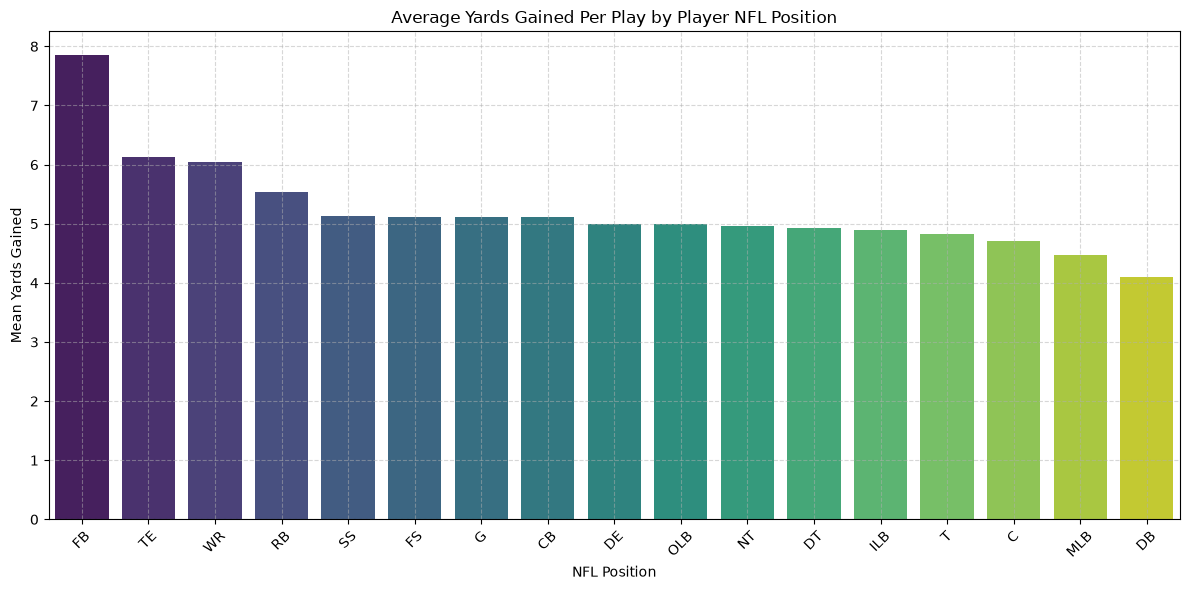

In [10]:
# 1. Recombine with all columns from player_play to ensure metrics are present
combined_df = pd.merge(merged_players_plays, games, on="game_id", how="inner")

print("=== Statistical Metrics Summary ===")
metrics = ["yards_gained", "expected_points_added", "expected_points", "pre_snap_home_team_win_probability"]

display(combined_df[metrics].describe())

# 2. Look at average yars gained by player position
plt.figure(figsize=(12, 6))
avg_yards_position = combined_df.groupby("nfl_position")["yards_gained"].mean().reset_index().sort_values(by="yards_gained", ascending=False)
sns.barplot(data=avg_yards_position, x="nfl_position", y="yards_gained", hue='nfl_position', palette="viridis", legend=False)
plt.title('Average Yards Gained Per Play by Player NFL Position')
plt.xlabel('NFL Position')
plt.ylabel("Mean Yards Gained")
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

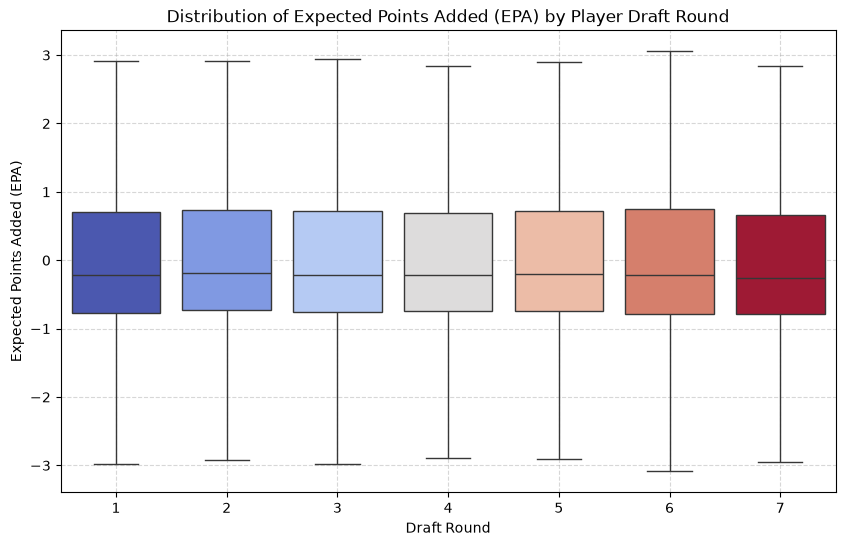

In [11]:
# 3. Let's analyze and plot the relationship between Expected Points Added (EPA) and Draft Round on the full dataset
plt.figure(figsize=(10, 6))
# Filter out placeholder draft rounds (-1)
valid_draft_df = combined_df[combined_df['draft_round'] > 0]
sns.boxplot(data=valid_draft_df, x='draft_round', y='expected_points_added', hue='draft_round', palette='coolwarm', showfliers=False, legend=False)
plt.title('Distribution of Expected Points Added (EPA) by Player Draft Round')
plt.xlabel('Draft Round')
plt.ylabel('Expected Points Added (EPA)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

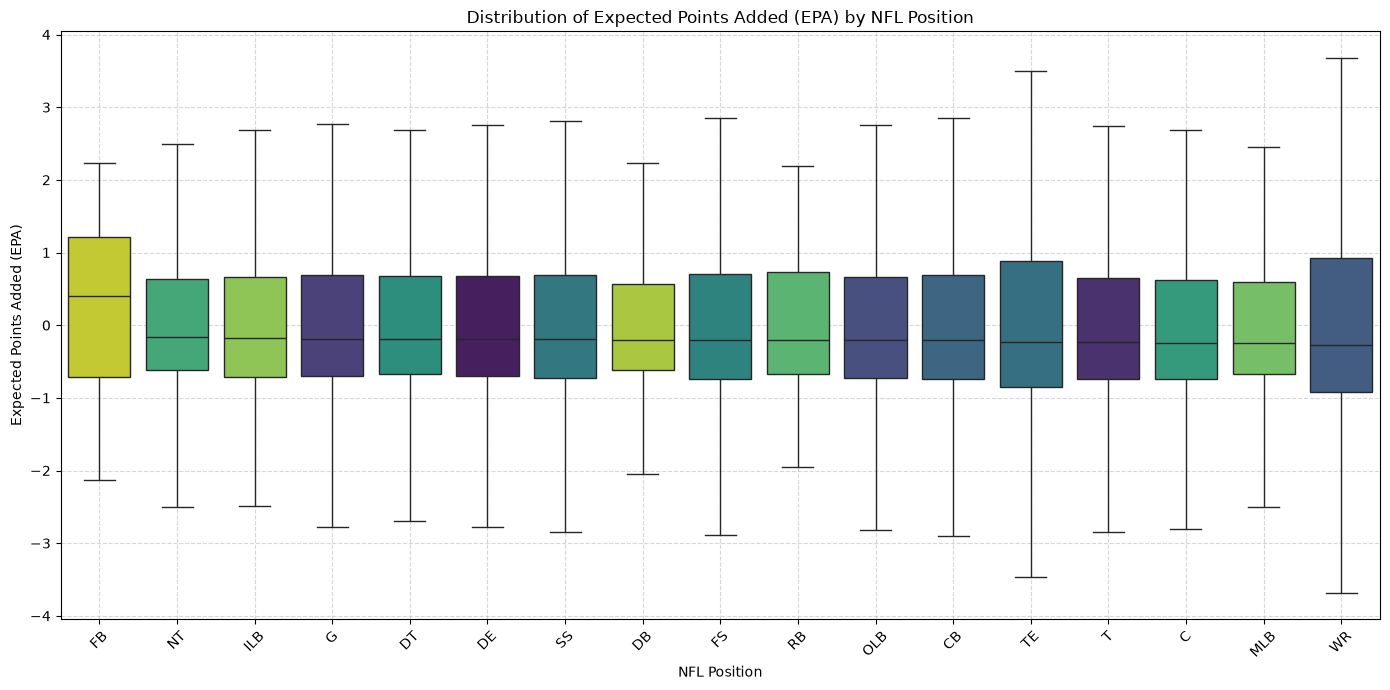

In [12]:
# Visualize the distribution of EPA by NFL Position using a box plot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

# Sort positions by their median EPA for better readability
position_order = combined_df.groupby('nfl_position')['expected_points_added'].median().sort_values(ascending=False).index

# Create a boxplot for Expected Points Added (EPA) by NFL Position
sns.boxplot(
    data=combined_df,
    x='nfl_position',
    y='expected_points_added',
    order=position_order,
    palette='viridis',
    hue='nfl_position',
    showfliers=False,
    legend=False
)

# plot title
plt.title('Distribution of Expected Points Added (EPA) by NFL Position')

# plot x label
plt.xlabel('NFL Position')
# plot y label
plt.ylabel('Expected Points Added (EPA)')
# plot grid 
plt.grid(True, linestyle='--', alpha=0.5)
# plot x ticks
plt.xticks(rotation=45)
# plot tight layout
plt.tight_layout()
# plot show graph
plt.show()

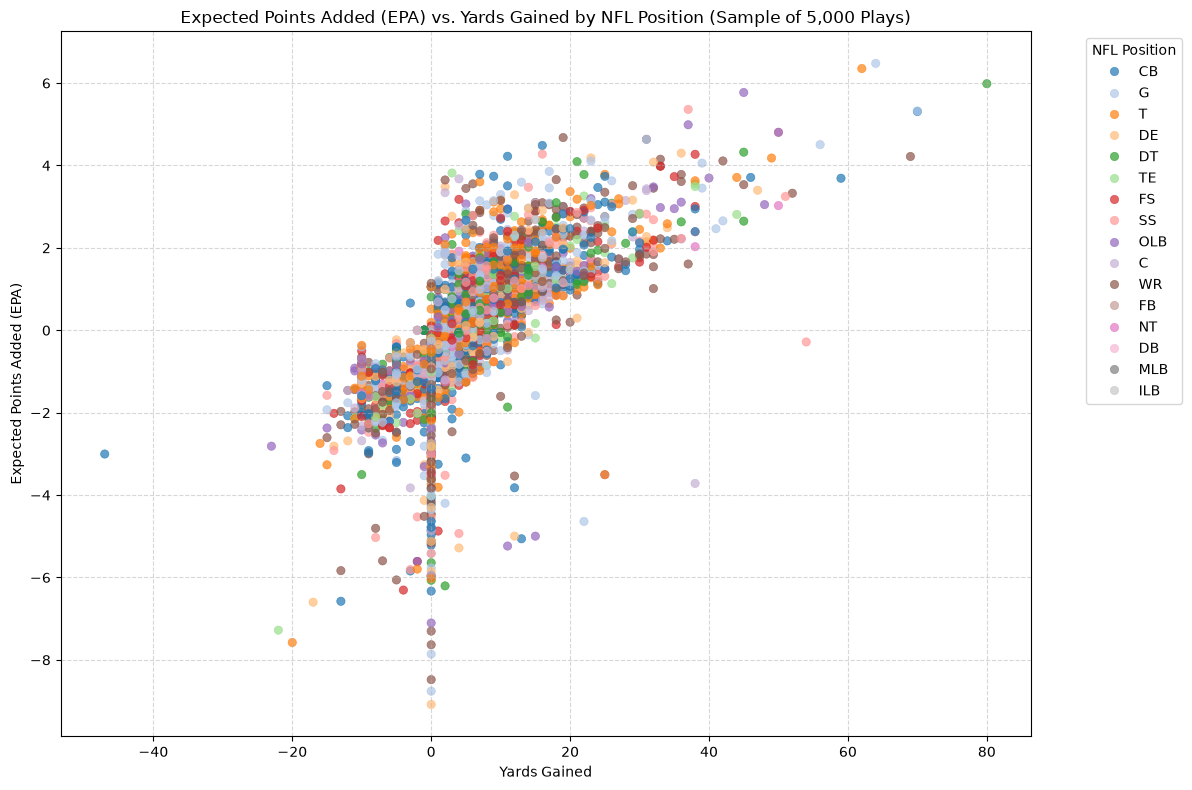

In [13]:
# Scatter plot of EPA versus yards_gained by position
import matplotlib.pyplot as plt
import seaborn as sns

# Sample a subset of the dataset if it is too dense, to keep the scatter plot clear and fast to render
sample_df = combined_df.dropna(subset=['expected_points_added', 'yards_gained']).sample(n=5000, random_state=42)

# create figure size for the scatterplot
plt.figure(figsize=(12, 8))

# scatterplot with different set parameters
sns.scatterplot(
    data=sample_df,
    x='yards_gained',
    y='expected_points_added',
    hue='nfl_position',
    palette='tab20',
    alpha=0.7,
    edgecolor=None
)

# plot title
plt.title('Expected Points Added (EPA) vs. Yards Gained by NFL Position (Sample of 5,000 Plays)')
# plot x label
plt.xlabel('Yards Gained')
# plot y label
plt.ylabel('Expected Points Added (EPA)')
# plot grid 
plt.grid(True, linestyle='--', alpha=0.5)
# plot legend
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='NFL Position')
# plot tight layout
plt.tight_layout()
# plot show graph
plt.show()

=== Average Time to Pressure by Position ===


,nfl_position,time_to_pressure
5,OLB,2.962140
0,DE,3.005151
2,ILB,3.016667
1,DT,3.148118
4,NT,3.337879
3,MLB,3.700000


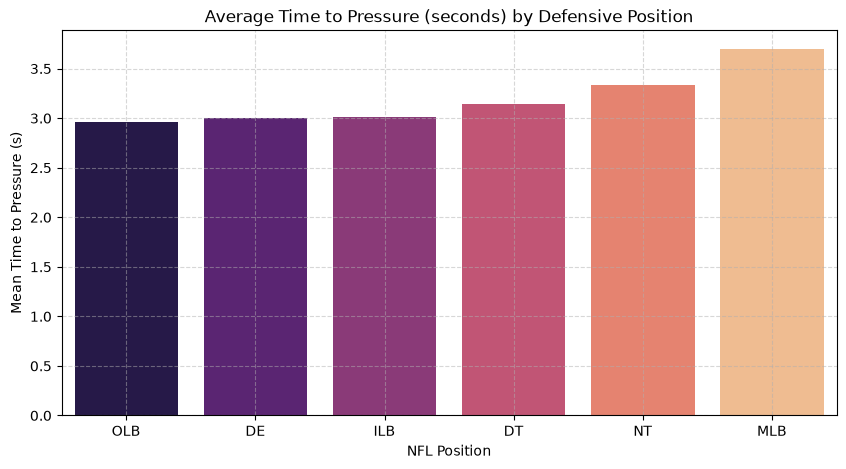

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for plays where pressure or a sack occurred, or a valid time_to_pressure was recorded
# Common pass rushing positions include DE, DT, OLB, NT, ILB, MLB
pass_rush_positions = ['DE', 'DT', 'OLB', 'NT', 'ILB', 'MLB']

# Drop NaN values in 'time_to_pressure' to focus on active rush events
pass_rush_df = combined_df[
    (combined_df['nfl_position'].isin(pass_rush_positions)) &
    (combined_df['time_to_pressure'].notna()) &
    (combined_df['time_to_pressure'] > 0)
]

# Calculate mean time to pressure by position
avg_pressure_time = pass_rush_df.groupby('nfl_position')['time_to_pressure'].mean().reset_index().sort_values(by='time_to_pressure')

# display the average pressure time
print("=== Average Time to Pressure by Position ===")
display(avg_pressure_time)

# Visualize the results
plt.figure(figsize=(10, 5))
# bar plot 
sns.barplot(data=avg_pressure_time, x='nfl_position', y='time_to_pressure', hue='nfl_position', palette='magma', legend=False)
# title
plt.title('Average Time to Pressure (seconds) by Defensive Position')
# x label
plt.xlabel('NFL Position')
# y label
plt.ylabel('Mean Time to Pressure (s)')
# grid
plt.grid(True, linestyle='--', alpha=0.5)
# plot show
plt.show()

We have the average Time to Pressure (seconds) for sack-eligible players grouped by their NFL position:

OLB (Outside Linebacker): 2.96 seconds DE (Defensive End): 3.01 seconds ILB (Inside Linebacker): 3.02 seconds DT (Defensive Tackle): 3.15 seconds NT (Nose Tackle): 3.34 seconds MLB (Middle Linebacker): 3.70 seconds Observations:

Edge Rushers Rule the Clock: Outside Linebackers (OLB) and Defensive Ends (DE) get to the quarterback fastest, consistently getting pressure in under 3 seconds. Interior Linemen: Defensive Tackles (DT) and Nose Tackles (NT) take slightly longer (3.15s to 3.34s), which is expected given they have to fight through double teams and travel through the interior "A/B gaps." Inside vs. Middle Linebackers: While ILBs show a fast average of 3.02s (likely heavily influenced by clean blitz packages), traditional Middle Linebackers (MLB) take the longest at 3.70s, often rushing from deeper depth or acting as delayed rushers.

In [16]:
# Filter pass rush records and aggregate by player to find the fastest individuals per position
# Minimum 5 recordings of time_to_pressure to filter out small sample outliers
pass_rush_filtered = combined_df[
    (combined_df['nfl_position'].isin(pass_rush_positions)) &
    (combined_df['time_to_pressure'].notna()) &
    (combined_df['time_to_pressure'] > 0)
]

# Filter for players with at least 5 pressure events to establish consistency
player_pressure_stats = pass_rush_filtered.groupby(['display_name', 'nfl_position']).agg(
    mean_time_to_pressure = ('time_to_pressure', 'mean'),
    pressure_event_count = ('time_to_pressure', 'count')
).reset_index()

# filter for players with at least 5 pressure events to establish consistency
consistent_rushers = player_pressure_stats[player_pressure_stats['pressure_event_count'] >= 5]

# Find the player with the minimum average time to pressure for each position
fastest_players_per_position = consistent_rushers.loc[
        consistent_rushers.groupby('nfl_position')['mean_time_to_pressure'].idxmin()
    ].sort_values(by='mean_time_to_pressure')

# Fastest players to pressure by defensive position (min 5 pressures)
print("===== Fastest Players to Pressure by Defensive Position (Min 5 Pressures) =====")
display(fastest_players_per_position)

===== Fastest Players to Pressure by Defensive Position (Min 5 Pressures) =====


,display_name,nfl_position,mean_time_to_pressure,pressure_event_count
4,Antwaun Powell-Ryland,OLB,2.540000,5
100,Ty Robinson,DT,2.660000,5
108,Will Anderson,DE,2.757143,245
19,Cameron Young,NT,2.960000,5
46,James Williams,ILB,3.016667,6
